In [3]:
pip install qiskit qiskit-nature qiskit-algorithms pyscf scipy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 12.1 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.4/23.4 MB 14.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 11.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-nature]0m [qiskit-nature]
Note: you may need to restart the kernel to use updated packages.


In [6]:
#make the modelcule
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.units import DistanceUnit

R = 0.8
driver = PySCFDriver(
    atom = f"He 0 0 0; H 0 0 {R}",
    unit = DistanceUnit.ANGSTROM,
    charge = 1,
    spin = 0,
    basis = "sto3g"
)
problem = driver.run()
print("n spatial orbitals:", problem.num_spatial_orbitals)
print("n electrons:", problem.num_particles)

n spatial orbitals: 2
n electrons: (1, 1)


In [12]:
from qiskit_nature.second_q.mappers import JordanWignerMapper

mapper = JordanWignerMapper()
fermionic_hamiltonian = (problem.hamiltonian.second_q_op())
qubit_hamiltonian = mapper.map(fermionic_hamiltonian)
print(qubit_hamiltonian)
print("number of qbits:", qubit_hamiltonian.num_qubits)

SparsePauliOp(['IIII', 'IIIZ', 'IIYY', 'IIXX', 'IIZI', 'IZII', 'YYII', 'XXII', 'ZIII', 'IIZZ', 'IZIZ', 'YYIZ', 'XXIZ', 'ZIIZ', 'IZYY', 'IZXX', 'YYYY', 'XXYY', 'YYXX', 'XXXX', 'ZIYY', 'ZIXX', 'IZZI', 'YYZI', 'XXZI', 'ZIZI', 'ZZII'],
              coeffs=[-2.90213083+0.j,  0.75284681+0.j,  0.05363257+0.j,  0.05363257+0.j,
  0.19701607+0.j,  0.75284681+0.j,  0.05363257+0.j,  0.05363257+0.j,
  0.19701607+0.j,  0.12689447+0.j,  0.23567567+0.j,  0.04337626+0.j,
  0.04337626+0.j,  0.1625523 +0.j,  0.04337626+0.j,  0.04337626+0.j,
  0.03565783+0.j,  0.03565783+0.j,  0.03565783+0.j,  0.03565783+0.j,
 -0.0102554 +0.j, -0.0102554 +0.j,  0.1625523 +0.j, -0.0102554 +0.j,
 -0.0102554 +0.j,  0.18783587+0.j,  0.12689447+0.j])
number of qbits: 4


In [17]:
from qiskit_nature.second_q.circuit.library import (
    HartreeFock,
    UCCSD
)
initial_state = HartreeFock(
    num_spatial_orbitals=problem.num_spatial_orbitals,
    num_particles=problem.num_particles,
    qubit_mapper=mapper
)
ansatz = UCCSD(
    num_spatial_orbitals=problem.num_spatial_orbitals,
    num_particles=problem.num_particles,
    qubit_mapper=mapper,
    initial_state=initial_state
)
print("Number of parameters:",
      ansatz.num_parameters)

Number of parameters: 3


In [18]:
print(ansatz.excitation_list)

[((0,), (1,)), ((2,), (3,)), ((0, 2), (1, 3))]


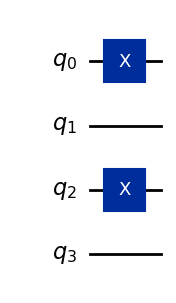

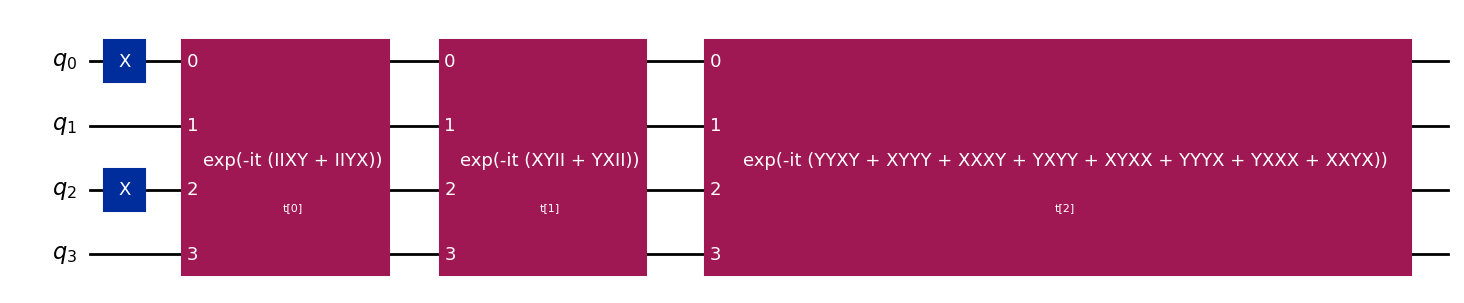

In [20]:
display(initial_state.draw("mpl"))
display(ansatz.decompose().draw("mpl"))

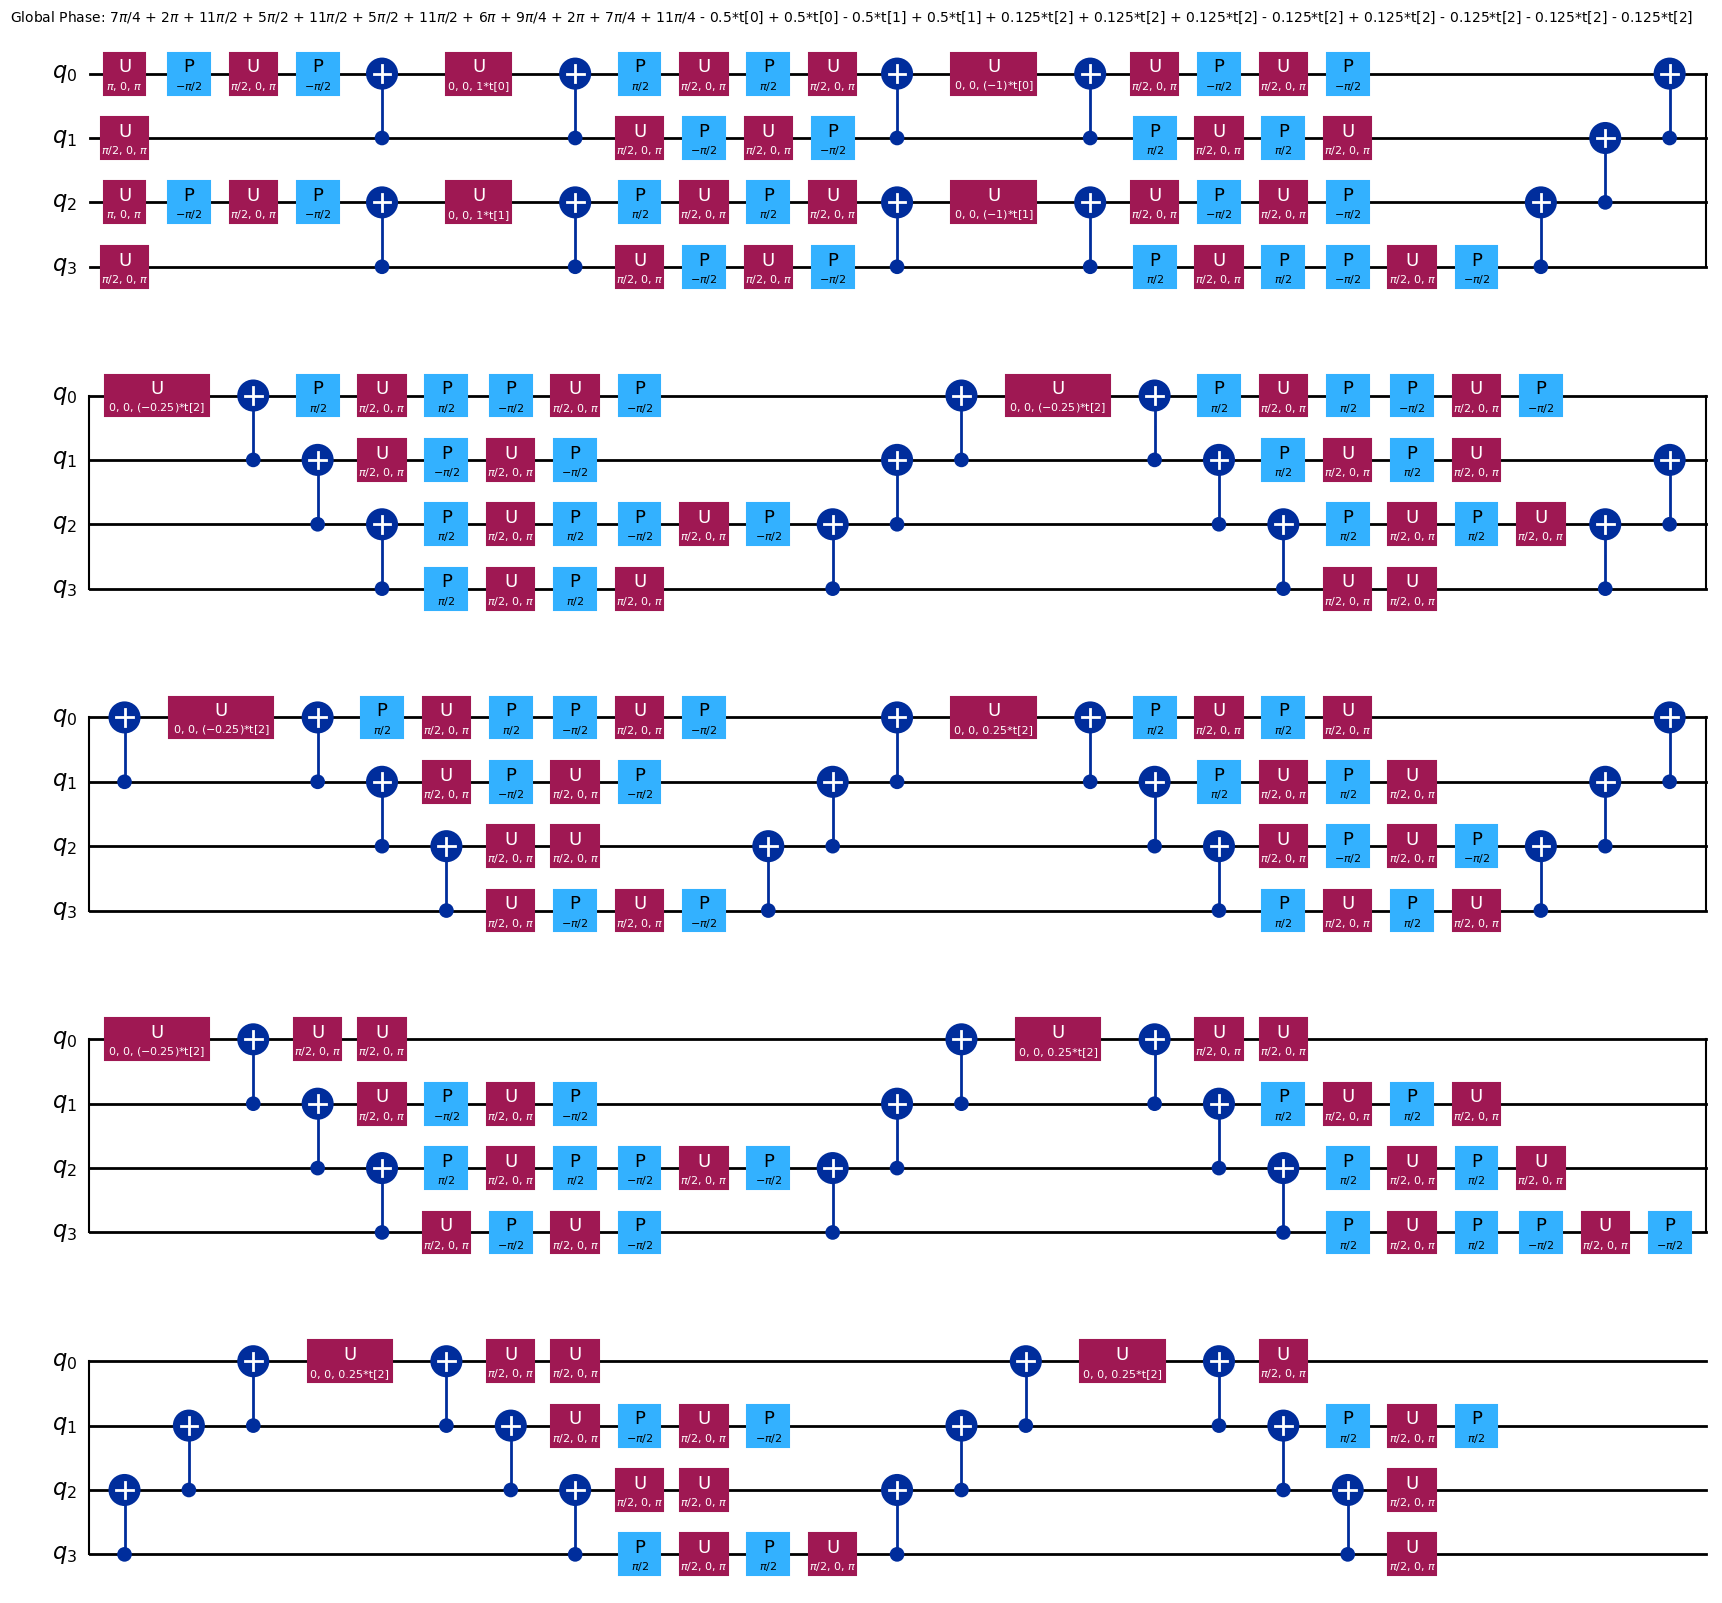

In [22]:
display(ansatz.decompose(reps=4).draw("mpl"))

In [24]:
import numpy as np

H_matrix = qubit_hamiltonian.to_matrix()

print(np.round(H_matrix.real, 3))
print("Matrix shape:", H_matrix.shape)

[[ 0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
   0.     0.     0.     0.     0.     0.   ]
 [ 0.    -2.556  0.174  0.     0.     0.     0.     0.     0.     0.
   0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.174 -1.349  0.     0.     0.     0.     0.     0.     0.
   0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.    -3.397  0.     0.     0.     0.     0.     0.
   0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.    -2.556  0.     0.     0.     0.174  0.
   0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.     0.    -4.169  0.     0.     0.     0.
   0.143  0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.     0.     0.    -3.254  0.     0.     0.143
   0.215  0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.     0.     0.     0.    -4.36   0.     0.
   0.     0.041  0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.     0.174  0.     0.     0.    -1.349  0.
   0.     0.    

In [37]:
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import SLSQP
import numpy as np

estimator = StatevectorEstimator()
optimizer = SLSQP(maxiter=200)
vqe = VQE(
    estimator=estimator,
    ansatz=ansatz,
    optimizer=optimizer,
    initial_point=np.zeros(ansatz.num_parameters)
)
result = vqe.compute_minimum_eigenvalue(qubit_hamiltonian)
electronic_energy = result.eigenvalue.real
nuclear_energy = (problem.hamiltonian.nuclear_repulsion_energy)
total_energy = electronic_energy + nuclear_energy
print("Electronic energy:", electronic_energy)
print("Nuclear repulsion:", nuclear_energy)
print("Total energy:", total_energy)

Electronic energy: -4.178651630162972
Nuclear repulsion: 1.3229430273
Total energy: -2.855708602862972


In [36]:
print("Optimal parameters:", result.optimal_point)
print("Function evaluations:", result.cost_function_evals)
print("Optimal energy:", result.eigenvalue)

Optimal parameters: [-0.01332632 -0.01332641 -0.06663096]
Function evaluations: 14
Optimal energy: -4.178651630162972


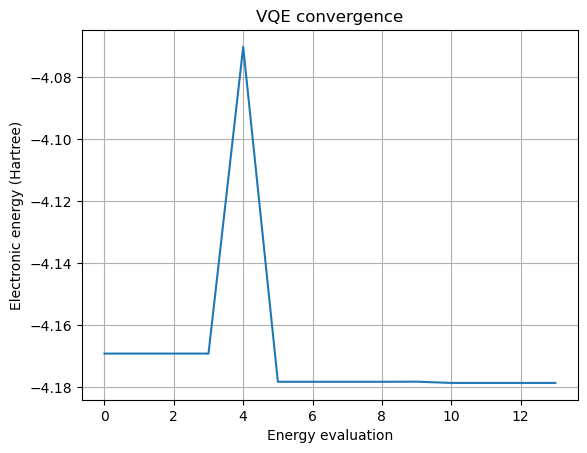

In [40]:
energy_history = []

def callback(eval_count, parameters, energy, metadata):
    energy_history.append(energy)

vqe = VQE(
    estimator=StatevectorEstimator(),
    ansatz=ansatz,
    optimizer=SLSQP(maxiter=200),
    initial_point=np.zeros(ansatz.num_parameters),
    callback=callback
)

result = vqe.compute_minimum_eigenvalue(qubit_hamiltonian)
import matplotlib.pyplot as plt

plt.plot(energy_history)
plt.xlabel("Energy evaluation")
plt.ylabel("Electronic energy (Hartree)")
plt.title("VQE convergence")
plt.grid(True)
plt.show()

In [46]:
from qiskit_nature.second_q.algorithms import (
    GroundStateEigensolver
)
from qiskit_algorithms import NumPyMinimumEigensolver

exact_solver = GroundStateEigensolver(
    mapper,
    NumPyMinimumEigensolver(
        filter_criterion=problem.get_default_filter_criterion()
    )
)
exact_result = exact_solver.solve(problem)

print("Exact total energy:",
      exact_result.total_energies[0].real)
print("VQE total energy:", total_energy)
print("VQE error:", total_energy - exact_result.total_energies[0].real)

Exact total energy: -2.85570862722801
VQE total energy: -2.855708602862972
VQE error: 2.4365037987195137e-08


In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE, NumPyMinimumEigensolver
from qiskit_algorithms.optimizers import SLSQP

from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.circuit.library import HartreeFock, UCCSD
from qiskit_nature.second_q.algorithms import GroundStateEigensolver
def HeHposenergymin(R,initial_point=None):
    start_time = time.perf_counter()
    driver = PySCFDriver(
        atom = f"He 0 0 0; H 0 0 {R}",
        unit = DistanceUnit.ANGSTROM,
        charge = 1,
        spin = 0,
        basis = "sto3g"
    )
    problem = driver.run()
    mapper = JordanWignerMapper()
    fermionic_hamiltonian = (problem.hamiltonian.second_q_op())
    qubit_hamiltonian = mapper.map(fermionic_hamiltonian)
    initial_state = HartreeFock(
        num_spatial_orbitals=problem.num_spatial_orbitals,
        num_particles=problem.num_particles,
        qubit_mapper=mapper
    )
    ansatz = UCCSD(
        num_spatial_orbitals=problem.num_spatial_orbitals,
        num_particles=problem.num_particles,
        qubit_mapper=mapper,
        initial_state=initial_state
    )
    estimator = StatevectorEstimator()
    optimizer = SLSQP(maxiter=200)
    if initial_point is None:
        initial_point = np.zeros(ansatz.num_parameters)
    vqe = VQE(
        estimator=estimator,
        ansatz=ansatz,
        optimizer=optimizer,
        initial_point=initial_point
    )
    
    result = vqe.compute_minimum_eigenvalue(qubit_hamiltonian)
    electronic_energy = result.eigenvalue.real
    nuclear_energy = (problem.hamiltonian.nuclear_repulsion_energy)
    total_energy = electronic_energy + nuclear_energy
    print("Electronic energy:", electronic_energy)
    print("Nuclear repulsion:", nuclear_energy)
    print("Total energy:", total_energy)
    exact_solver = GroundStateEigensolver(
        mapper,
        NumPyMinimumEigensolver(
            filter_criterion=problem.get_default_filter_criterion()
        )
    )
    exact_result = exact_solver.solve(problem)
    exact_energy = float(exact_result.total_energies[0].real)
    runtime = time.perf_counter() - start_time

    return {
        "R": R,
        "VQE_energy": total_energy,
        "Exact_energy": exact_energy,
        "Error": abs(total_energy - exact_energy),
        "Evaluations": result.cost_function_evals,
        "Runtime": runtime,
        "Optimal_parameters": np.asarray(result.optimal_point)
    }


In [63]:
R_values = np.linspace(0.5, 3.0, 26)

results = []
previous_parameters = None

for i, R in enumerate(R_values):

    data = HeHposenergymin(
        R,
        initial_point=previous_parameters
    )

    results.append(data)

    # Warm-start the next bond length
    previous_parameters = data["Optimal_parameters"]

    print(
        f"{i+1}/{len(R_values)} | "
        f"R = {R:.2f} Å | "
        f"VQE = {data['VQE_energy']:.6f} Ha | "
        f"Error = {data['Error']:.2e} Ha"
    )

df = pd.DataFrame(results)

# Save numerical results
df.drop(columns=["Optimal_parameters"]).to_csv(
    "HeH_PES_results.csv",
    index=False
)

print(df.head())


/opt/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/opt/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


1/26 | R = 0.50 Å | VQE = -2.640715 Ha | Error = 7.50e-11 Ha
2/26 | R = 0.60 Å | VQE = -2.770009 Ha | Error = 3.54e-12 Ha
3/26 | R = 0.70 Å | VQE = -2.830483 Ha | Error = 7.39e-12 Ha
4/26 | R = 0.80 Å | VQE = -2.855709 Ha | Error = 3.81e-11 Ha
5/26 | R = 0.90 Å | VQE = -2.862618 Ha | Error = 7.38e-12 Ha
6/26 | R = 1.00 Å | VQE = -2.860205 Ha | Error = 1.24e-07 Ha
7/26 | R = 1.10 Å | VQE = -2.853516 Ha | Error = 6.95e-08 Ha
8/26 | R = 1.20 Å | VQE = -2.845425 Ha | Error = 1.05e-07 Ha
9/26 | R = 1.30 Å | VQE = -2.837497 Ha | Error = 7.71e-08 Ha
10/26 | R = 1.40 Å | VQE = -2.830489 Ha | Error = 1.80e-08 Ha
11/26 | R = 1.50 Å | VQE = -2.824683 Ha | Error = 3.54e-10 Ha
12/26 | R = 1.60 Å | VQE = -2.820091 Ha | Error = 1.53e-08 Ha
13/26 | R = 1.70 Å | VQE = -2.816590 Ha | Error = 3.06e-08 Ha
14/26 | R = 1.80 Å | VQE = -2.813996 Ha | Error = 3.20e-08 Ha
15/26 | R = 1.90 Å | VQE = -2.812117 Ha | Error = 2.38e-08 Ha
16/26 | R = 2.00 Å | VQE = -2.810780 Ha | Error = 1.41e-08 Ha
17/26 | R = 2.10 

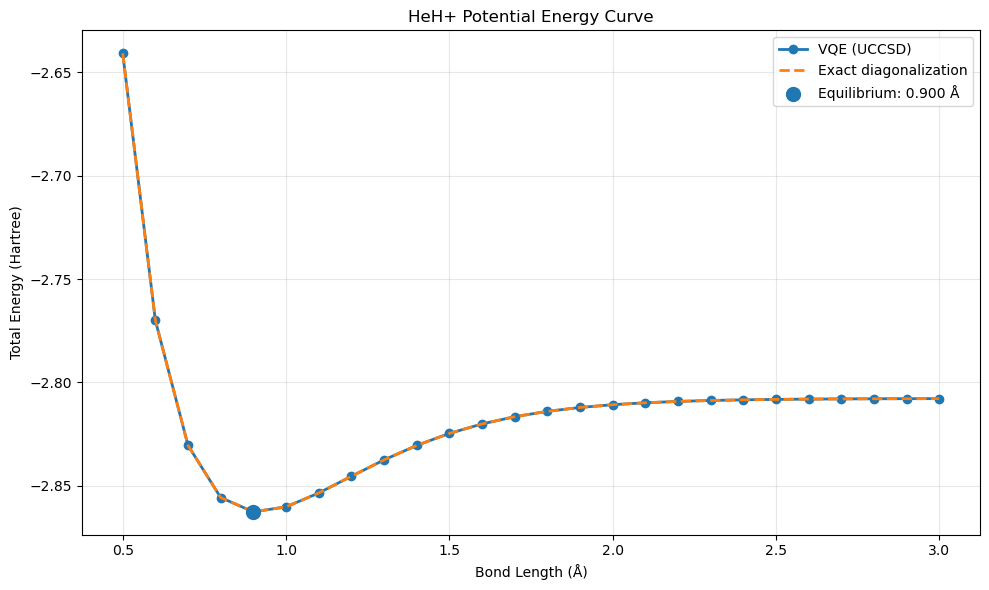

Equilibrium bond length: 0.9000 Å
Minimum energy: -2.86261758 Hartree


In [64]:
plt.figure(figsize=(10, 6))

plt.plot(
    df["R"],
    df["VQE_energy"],
    "o-",
    label="VQE (UCCSD)",
    linewidth=2
)

plt.plot(
    df["R"],
    df["Exact_energy"],
    "--",
    label="Exact diagonalization",
    linewidth=2
)

minimum_index = df["VQE_energy"].idxmin()

R_eq = df.loc[minimum_index, "R"]
E_min = df.loc[minimum_index, "VQE_energy"]

plt.scatter(
    R_eq, E_min,
    s=100,
    zorder=5,
    label=f"Equilibrium: {R_eq:.3f} Å"
)

plt.xlabel("Bond Length (Å)")
plt.ylabel("Total Energy (Hartree)")
plt.title("HeH+ Potential Energy Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("HeH_PES.png", dpi=300)
plt.show()

print(f"Equilibrium bond length: {R_eq:.4f} Å")
print(f"Minimum energy: {E_min:.8f} Hartree")


In [66]:
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE, NumPyMinimumEigensolver
from qiskit_algorithms.optimizers import SLSQP, COBYLA, L_BFGS_B

from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import (
    JordanWignerMapper, ParityMapper
)
from qiskit_nature.second_q.circuit.library import HartreeFock, UCCSD
from qiskit_nature.second_q.algorithms import GroundStateEigensolver
from qiskit_nature.units import DistanceUnit

from qiskit.circuit.library import real_amplitudes
from qiskit import transpile

import numpy as np
import pandas as pd
import time


def benchmark_HeH(
    R,
    mapping="JW",
    ansatz_type="UCCSD",
    optimizer_type="SLSQP",
    basis="sto3g"
):
    # Construct molecule
    driver = PySCFDriver(
        atom=f"He 0 0 0; H 0 0 {R}",
        unit=DistanceUnit.ANGSTROM,
        charge=1,
        spin=0,
        basis=basis
    )
    problem = driver.run()

    # Choose mapping
    if mapping == "JW":
        mapper = JordanWignerMapper()
    elif mapping == "Parity":
        mapper = ParityMapper(
            num_particles=problem.num_particles
        )
    else:
        raise ValueError("Unknown mapping")

    H = mapper.map(problem.hamiltonian.second_q_op())

    # Hartree-Fock reference
    hf = HartreeFock(
        num_spatial_orbitals=problem.num_spatial_orbitals,
        num_particles=problem.num_particles,
        qubit_mapper=mapper
    )

    # Choose ansatz
    if ansatz_type == "UCCSD":
        ansatz = UCCSD(
            num_spatial_orbitals=problem.num_spatial_orbitals,
            num_particles=problem.num_particles,
            qubit_mapper=mapper,
            initial_state=hf
        )

    elif ansatz_type == "RealAmplitudes":
        # General-purpose circuit, does not conserve
        # electron number automatically.
        from qiskit import QuantumCircuit

        ansatz = QuantumCircuit(H.num_qubits)
        ansatz.compose(hf, inplace=True)
        ansatz.compose(
            real_amplitudes(H.num_qubits, reps=2),
            inplace=True
        )

    else:
        raise ValueError("Unknown ansatz")

    # Choose optimizer
    optimizers = {
        "SLSQP": SLSQP(maxiter=200),
        "COBYLA": COBYLA(maxiter=200),
        "L_BFGS_B": L_BFGS_B(maxiter=200)
    }
    optimizer = optimizers[optimizer_type]

    # Circuit resource metrics
    # Count logical decomposed gates, not hardware-native gates.
    circuit = ansatz.decompose(reps=10)

    two_qubit_gates = sum(
        count for gate, count in circuit.count_ops().items()
        if gate in ["cx", "cz", "swap", "ecr", "rxx", "ryy", "rzz"]
    )

    # VQE calculation
    start = time.perf_counter()

    vqe = VQE(
        estimator=StatevectorEstimator(),
        ansatz=ansatz,
        optimizer=optimizer,
        initial_point=np.zeros(ansatz.num_parameters)
    )

    result = vqe.compute_minimum_eigenvalue(H)

    runtime = time.perf_counter() - start

    nuclear = problem.hamiltonian.nuclear_repulsion_energy
    vqe_energy = float(result.eigenvalue.real + nuclear)

    # Physical-sector exact reference
    exact_solver = GroundStateEigensolver(
        mapper,
        NumPyMinimumEigensolver(
            filter_criterion=problem.get_default_filter_criterion()
        )
    )

    exact_result = exact_solver.solve(problem)
    exact_energy = float(exact_result.total_energies[0].real)

    return {
        "R": R,
        "Mapping": mapping,
        "Ansatz": ansatz_type,
        "Optimizer": optimizer_type,
        "Basis": basis,
        "Qubits": H.num_qubits,
        "Parameters": ansatz.num_parameters,
        "Circuit_depth": circuit.depth(),
        "Two_qubit_gates": two_qubit_gates,
        "Evaluations": result.cost_function_evals,
        "Runtime": runtime,
        "VQE_energy": vqe_energy,
        "Exact_energy": exact_energy,
        "Error": abs(vqe_energy - exact_energy)
    }


In [67]:

configurations = [
    ("JW", "UCCSD", "SLSQP"),
    ("JW", "UCCSD", "COBYLA"),
    ("JW", "RealAmplitudes", "SLSQP"),
    ("JW", "RealAmplitudes", "COBYLA"),
    ("Parity", "UCCSD", "SLSQP"),
    ("JW", "UCCSD", "L_BFGS_B")
]

results = []

for mapping, ansatz, optimizer in configurations:
    print(f"Testing: {mapping}, {ansatz}, {optimizer}")

    data = benchmark_HeH(
        R=0.8,
        mapping=mapping,
        ansatz_type=ansatz,
        optimizer_type=optimizer
    )

    results.append(data)

df = pd.DataFrame(results)

print(df[[
    "Mapping", "Ansatz", "Optimizer",
    "Qubits", "Two_qubit_gates",
    "Error", "Runtime"
]].to_string(index=False))

df.to_csv("HeH_configuration_comparison.csv", index=False)


Testing: JW, UCCSD, SLSQP


/opt/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/opt/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


Testing: JW, UCCSD, COBYLA
Testing: JW, RealAmplitudes, SLSQP
Testing: JW, RealAmplitudes, COBYLA
Testing: Parity, UCCSD, SLSQP
Testing: JW, UCCSD, L_BFGS_B
Mapping         Ansatz Optimizer  Qubits  Two_qubit_gates        Error  Runtime
     JW          UCCSD     SLSQP       4               56 2.436504e-08 0.098140
     JW          UCCSD    COBYLA       4               56 1.016632e-08 0.288896
     JW RealAmplitudes     SLSQP       4                6 1.598273e+00 0.041427
     JW RealAmplitudes    COBYLA       4                6 1.813902e-01 0.219809
 Parity          UCCSD     SLSQP       2                4 2.437253e-08 0.046377
     JW          UCCSD  L_BFGS_B       4               56 7.381651e-12 0.131076


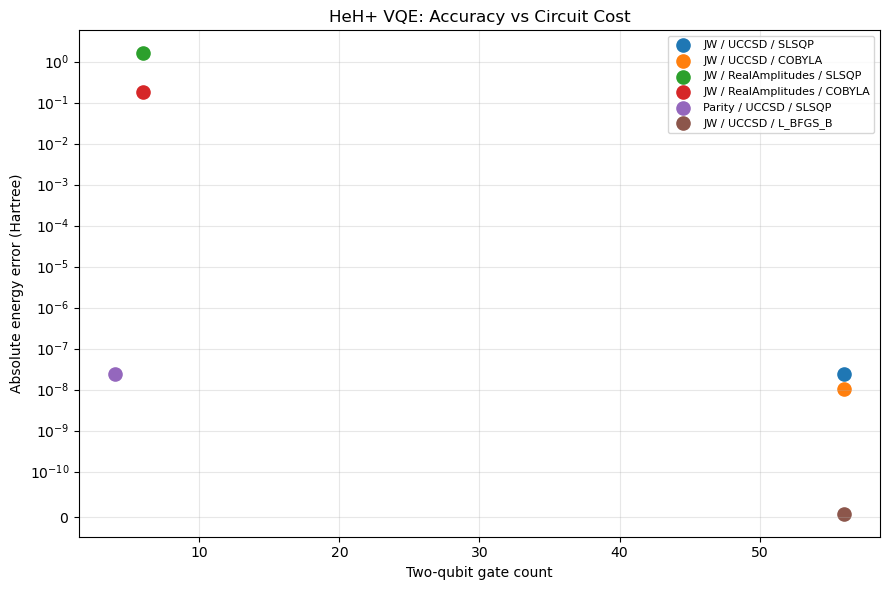

In [68]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for _, row in df.iterrows():
    label = (
        f"{row['Mapping']} / "
        f"{row['Ansatz']} / "
        f"{row['Optimizer']}"
    )

    plt.scatter(
        row["Two_qubit_gates"],
        row["Error"],
        s=90,
        label=label
    )

plt.xlabel("Two-qubit gate count")
plt.ylabel("Absolute energy error (Hartree)")
plt.yscale("symlog", linthresh=1e-10)
plt.title("HeH+ VQE: Accuracy vs Circuit Cost")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


/opt/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/opt/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


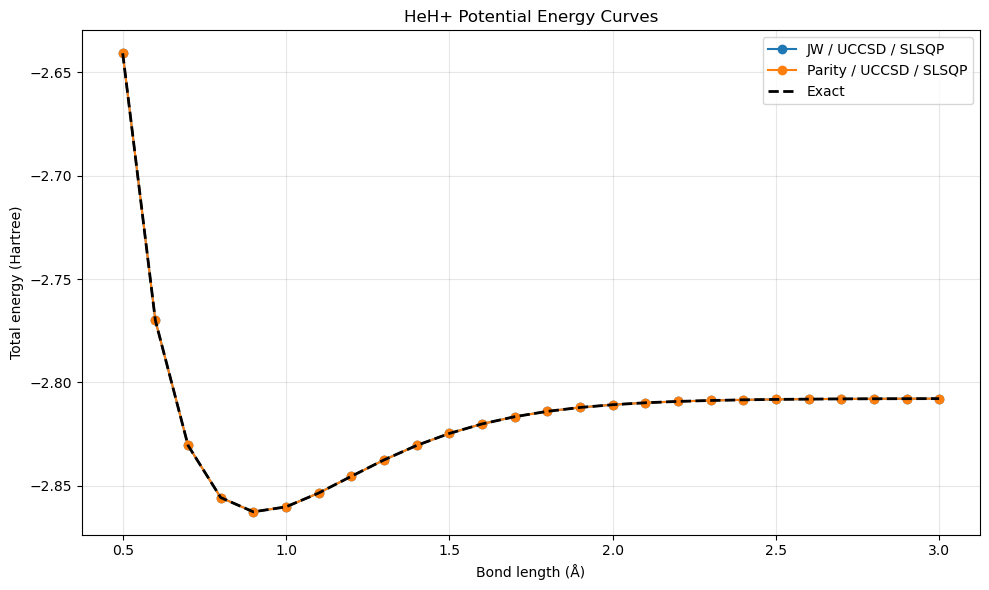

In [73]:

R_values = np.linspace(0.5, 3.0, 26)

selected = [
    ("JW", "UCCSD", "SLSQP"),
    ("Parity", "UCCSD", "SLSQP"),
]

all_results = []

for mapping, ansatz, optimizer in selected:
    for R in R_values:
        data = benchmark_HeH(
            R=R,
            mapping=mapping,
            ansatz_type=ansatz,
            optimizer_type=optimizer
        )
        all_results.append(data)

curve_df = pd.DataFrame(all_results)
curve_df.to_csv("HeH_full_benchmark.csv", index=False)

plt.figure(figsize=(10, 6))

for (mapping, ansatz, optimizer), group in curve_df.groupby(
    ["Mapping", "Ansatz", "Optimizer"]
):
    plt.plot(
        group["R"],
        group["VQE_energy"],
        "o-",
        label=f"{mapping} / {ansatz} / {optimizer}"
    )

reference = curve_df[
    (curve_df["Mapping"] == "JW") &
    (curve_df["Ansatz"] == "UCCSD")
].sort_values("R")

plt.plot(
    reference["R"],
    reference["Exact_energy"],
    "k--",
    label="Exact",
    linewidth=2
)

plt.xlabel("Bond length (Å)")
plt.ylabel("Total energy (Hartree)")
plt.title("HeH+ Potential Energy Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [74]:
pip install -U qiskit qiskit-ibm-runtime

  Using cached python_dateutil-3.0.0-py2.py3-none-any.whl.metadata (8.2 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 21.7 MB/s eta 0:00:00
Using cached python_dateutil-3.0.0-py2.py3-none-any.whl (94 kB)
  Attempting uninstall: python-dateutil
    Found existing installation: python-dateutil None
error: uninstall-no-record-file

× Cannot uninstall python-dateutil None
╰─> The package's contents are unknown: no RECORD file was found for python-dateutil.

hint: You might be able to recover from this via: pip install --force-reinstall --no-deps python-dateutil==2.9.0.post0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/3 [python-dateutil]
Note: you may need to restart the kernel to use updated packages.


In [91]:
import os
from qiskit_ibm_runtime import QiskitRuntimeService

# Store credentials in environment variables; never commit them.
QiskitRuntimeService.save_account(
    token=os.environ["QISKIT_IBM_TOKEN"],
    instance=os.environ["QISKIT_IBM_INSTANCE"],
    set_as_default=True,
    overwrite=True
)

In [77]:
service = QiskitRuntimeService()

backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=2
)

print("Selected QPU:", backend.name)

Selected QPU: ibm_fez


In [78]:

import numpy as np

from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import SLSQP

from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import ParityMapper
from qiskit_nature.second_q.circuit.library import HartreeFock, UCCSD
from qiskit_nature.units import DistanceUnit

R = 0.8

driver = PySCFDriver(
    atom=f"He 0 0 0; H 0 0 {R}",
    unit=DistanceUnit.ANGSTROM,
    charge=1,
    spin=0,
    basis="sto3g"
)

problem = driver.run()

mapper = ParityMapper(
    num_particles=problem.num_particles
)

H = mapper.map(
    problem.hamiltonian.second_q_op()
)

hf = HartreeFock(
    num_spatial_orbitals=problem.num_spatial_orbitals,
    num_particles=problem.num_particles,
    qubit_mapper=mapper
)

ansatz = UCCSD(
    num_spatial_orbitals=problem.num_spatial_orbitals,
    num_particles=problem.num_particles,
    qubit_mapper=mapper,
    initial_state=hf
)

# Optimize locally, without hardware noise
vqe = VQE(
    estimator=StatevectorEstimator(),
    ansatz=ansatz,
    optimizer=SLSQP(maxiter=200),
    initial_point=np.zeros(ansatz.num_parameters)
)

result = vqe.compute_minimum_eigenvalue(H)

optimal_parameters = result.optimal_point

nuclear_energy = float(
    problem.hamiltonian.nuclear_repulsion_energy
)

ideal_energy = float(result.eigenvalue.real) + nuclear_energy

print("Qubits:", H.num_qubits)
print("Ideal energy:", ideal_energy)
print("Optimal parameters:", optimal_parameters)


Qubits: 2
Ideal energy: -2.855708602855482
Optimal parameters: [-0.01332641 -0.01332633 -0.06663098]


/opt/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/opt/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


Original qubits: 2
Transpiled depth: 9
Hardware gates: OrderedDict({'sx': 8, 'rz': 6, 'cz': 2})


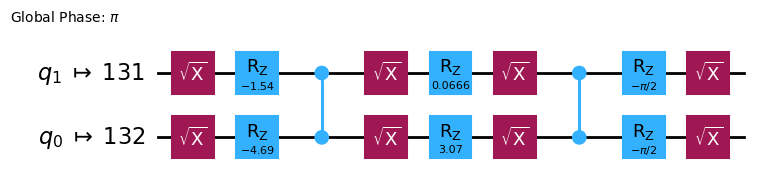

In [80]:
from qiskit.transpiler import generate_preset_pass_manager

# Replace symbolic parameters with optimized values
optimized_circuit = ansatz.assign_parameters(
    optimal_parameters
)

# Compile for the selected hardware
pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=3,
    seed_transpiler=42
)

isa_circuit = pm.run(optimized_circuit)

# Map the Hamiltonian to physical qubit positions
isa_hamiltonian = H.apply_layout(isa_circuit.layout)

print("Original qubits:", optimized_circuit.num_qubits)
print("Transpiled depth:", isa_circuit.depth())
print("Hardware gates:", isa_circuit.count_ops())

isa_circuit.draw("mpl", idle_wires=False)


In [81]:

from qiskit_ibm_runtime.executor_estimator import Estimator

estimator = Estimator(mode=backend)

# Start without additional error mitigation
estimator.options.resilience_level = 0
estimator.options.default_shots = 4096

# Submit the circuit to the actual QPU
job = estimator.run([
    (isa_circuit, isa_hamiltonian)
])

print("Job ID:", job.job_id())
print("Job status:", job.status())


Job ID: dbsf970k09pc73b03r7g
Job status: QUEUED


In [82]:
hardware_result = job.result()

pub_result = hardware_result[0]

hardware_electronic_energy = float(
    np.asarray(pub_result.data.evs).item()
)

hardware_energy = (
    hardware_electronic_energy + nuclear_energy
)

hardware_std = float(
    np.asarray(pub_result.data.stds).item()
)

print("Ideal energy:", ideal_energy)
print("Hardware energy:", hardware_energy)
print("Reported standard uncertainty:", hardware_std)

print(
    "Absolute difference:",
    abs(hardware_energy - ideal_energy)
)


Ideal energy: -2.855708602855482
Hardware energy: -2.7802713082198967
Reported standard uncertainty: 0.006375656612319923
Absolute difference: 0.07543729463558524


In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE, NumPyMinimumEigensolver
from qiskit_algorithms.optimizers import SLSQP

from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import ParityMapper
from qiskit_nature.second_q.circuit.library import HartreeFock, UCCSD
from qiskit_nature.second_q.algorithms import GroundStateEigensolver
from qiskit_nature.units import DistanceUnit

R_values = np.linspace(0.5, 3.0, 26)

circuits = []
hamiltonians = []
records = []

previous_parameters = None

for R in R_values:
    driver = PySCFDriver(
        atom=f"He 0 0 0; H 0 0 {R}",
        unit=DistanceUnit.ANGSTROM,
        charge=1,
        spin=0,
        basis="sto3g"
    )

    problem = driver.run()
    mapper = ParityMapper(num_particles=problem.num_particles)

    H = mapper.map(problem.hamiltonian.second_q_op())

    hf = HartreeFock(
        num_spatial_orbitals=problem.num_spatial_orbitals,
        num_particles=problem.num_particles,
        qubit_mapper=mapper
    )

    ansatz = UCCSD(
        num_spatial_orbitals=problem.num_spatial_orbitals,
        num_particles=problem.num_particles,
        qubit_mapper=mapper,
        initial_state=hf
    )

    initial_point = (
        np.zeros(ansatz.num_parameters)
        if previous_parameters is None
        else previous_parameters
    )

    vqe = VQE(
        estimator=StatevectorEstimator(),
        ansatz=ansatz,
        optimizer=SLSQP(maxiter=200),
        initial_point=initial_point
    )

    result = vqe.compute_minimum_eigenvalue(H)

    previous_parameters = np.asarray(result.optimal_point)

    # Bind optimal parameters
    optimized_circuit = ansatz.assign_parameters(
        result.optimal_point
    )

    circuits.append(optimized_circuit)
    hamiltonians.append(H)

    nuclear_energy = float(
        problem.hamiltonian.nuclear_repulsion_energy
    )

    ideal_energy = float(result.eigenvalue.real) + nuclear_energy

    exact_solver = GroundStateEigensolver(
        mapper,
        NumPyMinimumEigensolver(
            filter_criterion=problem.get_default_filter_criterion()
        )
    )

    exact_result = exact_solver.solve(problem)

    exact_energy = float(
        exact_result.total_energies[0].real
    )

    records.append({
        "R": R,
        "Ideal_VQE": ideal_energy,
        "Exact": exact_energy,
        "Nuclear_energy": nuclear_energy
    })

    print(f"R={R:.2f} Å | Ideal={ideal_energy:.8f}")

df = pd.DataFrame(records)
df.to_csv("HeH_local_reference.csv", index=False)


R=0.50 Å | Ideal=-2.64071459
R=0.60 Å | Ideal=-2.77000938
R=0.70 Å | Ideal=-2.83048296
R=0.80 Å | Ideal=-2.85570863
R=0.90 Å | Ideal=-2.86261758
R=1.00 Å | Ideal=-2.86020500
R=1.10 Å | Ideal=-2.85351612
R=1.20 Å | Ideal=-2.84542523
R=1.30 Å | Ideal=-2.83749680
R=1.40 Å | Ideal=-2.83048905
R=1.50 Å | Ideal=-2.82468268
R=1.60 Å | Ideal=-2.82009110
R=1.70 Å | Ideal=-2.81658980
R=1.80 Å | Ideal=-2.81399600
R=1.90 Å | Ideal=-2.81211747
R=2.00 Å | Ideal=-2.81078009
R=2.10 Å | Ideal=-2.80983962
R=2.20 Å | Ideal=-2.80918467
R=2.30 Å | Ideal=-2.80873209
R=2.40 Å | Ideal=-2.80842146
R=2.50 Å | Ideal=-2.80820967
R=2.60 Å | Ideal=-2.80806609
R=2.70 Å | Ideal=-2.80796973
R=2.80 Å | Ideal=-2.80790534
R=2.90 Å | Ideal=-2.80786267
R=3.00 Å | Ideal=-2.80783461


In [85]:

from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.transpiler import generate_preset_pass_manager

service = QiskitRuntimeService()

backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=2
)

print("Using:", backend.name)

pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=3,
    seed_transpiler=42
)

pubs = []

for circuit, H in zip(circuits, hamiltonians):
    isa_circuit = pm.run(circuit)

    # Hamiltonian must follow the transpiled layout
    isa_H = H.apply_layout(isa_circuit.layout)

    pubs.append((isa_circuit, isa_H))

print("Prepared", len(pubs), "hardware evaluations")


Using: ibm_fez
Prepared 26 hardware evaluations


In [86]:

from qiskit_ibm_runtime.executor_estimator import Estimator

estimator = Estimator(mode=backend)

estimator.options.default_shots = 4096
estimator.options.resilience_level = 0

# Test the first point before committing to all 26.
test_job = estimator.run([pubs[0]])

print("Test job ID:", test_job.job_id())

test_result = test_job.result()
print("Test electronic energy:", test_result[0].data.evs)


Test job ID: dbsfe90k09pc73b0401g
Test electronic energy: -4.642653381962388


In [87]:

job = estimator.run(pubs)

job_id = job.job_id()

print("IBM QPU:", backend.name)
print("Job ID:", job_id)

# Save ID so you can retrieve the job later
with open("HeH_hardware_job_id.txt", "w") as f:
    f.write(job_id)


IBM QPU: ibm_fez
Job ID: dbsff20k09pc73b040r0


In [88]:

hardware_results = job.result()

hardware_energies = []
hardware_errors = []

for i, pub_result in enumerate(hardware_results):
    electronic_energy = float(
        np.asarray(pub_result.data.evs).item()
    )

    uncertainty = float(
        np.asarray(pub_result.data.stds).item()
    )

    total_energy = (
        electronic_energy + df.loc[i, "Nuclear_energy"]
    )

    hardware_energies.append(total_energy)
    hardware_errors.append(uncertainty)

df["Hardware_QPU"] = hardware_energies
df["Hardware_std"] = hardware_errors

df["Hardware_abs_error"] = abs(
    df["Hardware_QPU"] - df["Exact"]
)

df.to_csv("HeH_hardware_results.csv", index=False)

print(df.to_string(index=False))


  R  Ideal_VQE     Exact  Nuclear_energy  Hardware_QPU  Hardware_std  Hardware_abs_error
0.5  -2.640715 -2.640715        2.116709     -2.520208      0.007788            0.120507
0.6  -2.770009 -2.770009        1.763924     -2.675996      0.006968            0.094013
0.7  -2.830483 -2.830483        1.511935     -2.741346      0.006729            0.089137
0.8  -2.855709 -2.855709        1.322943     -2.776011      0.006518            0.079697
0.9  -2.862618 -2.862618        1.175949     -2.787525      0.006457            0.075092
1.0  -2.860205 -2.860205        1.058354     -2.799221      0.006174            0.060984
1.1  -2.853516 -2.853516        0.962140     -2.801402      0.006123            0.052114
1.2  -2.845425 -2.845425        0.881962     -2.794623      0.006045            0.050803
1.3  -2.837497 -2.837497        0.814119     -2.781811      0.006090            0.055686
1.4  -2.830489 -2.830489        0.755967     -2.787608      0.005851            0.042881
1.5  -2.824683 -2.824

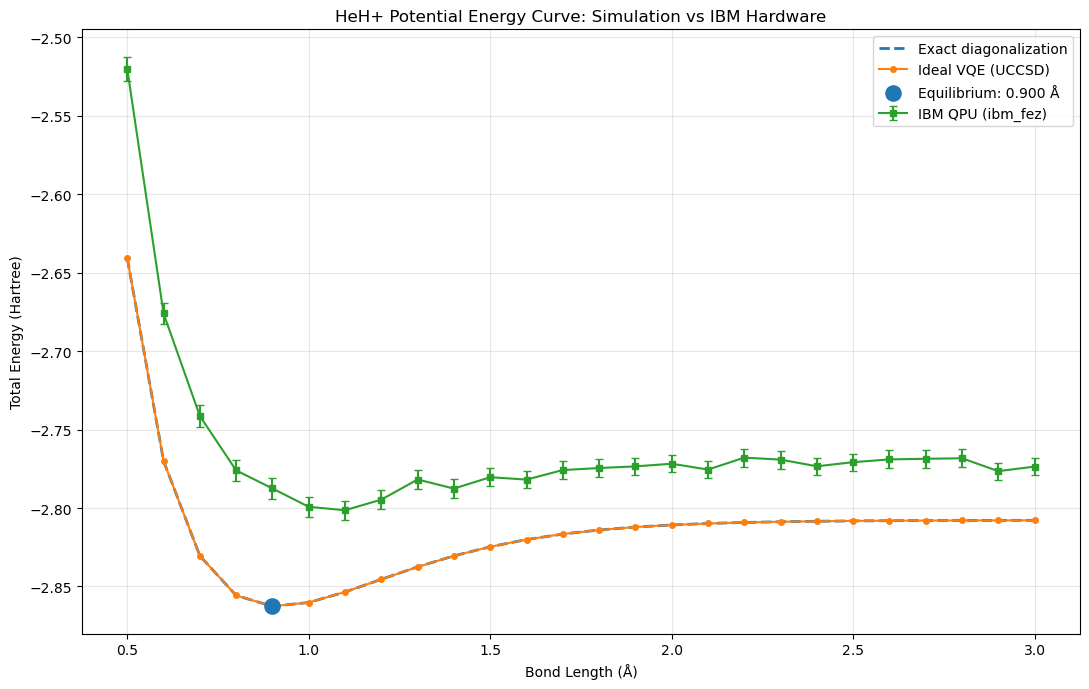

In [89]:

plt.figure(figsize=(11, 7))

# Exact reference
plt.plot(
    df["R"],
    df["Exact"],
    "--",
    linewidth=2,
    label="Exact diagonalization"
)

# Ideal VQE
plt.plot(
    df["R"],
    df["Ideal_VQE"],
    "o-",
    markersize=4,
    linewidth=1.5,
    label="Ideal VQE (UCCSD)"
)

# Real IBM hardware with uncertainty bars
plt.errorbar(
    df["R"],
    df["Hardware_QPU"],
    yerr=df["Hardware_std"],
    fmt="s-",
    markersize=4,
    capsize=3,
    linewidth=1.5,
    label=f"IBM QPU ({backend.name})"
)

# Mark equilibrium from exact curve
minimum_index = df["Exact"].idxmin()
R_eq = df.loc[minimum_index, "R"]
E_eq = df.loc[minimum_index, "Exact"]

plt.scatter(
    R_eq,
    E_eq,
    s=120,
    zorder=5,
    label=f"Equilibrium: {R_eq:.3f} Å"
)

plt.xlabel("Bond Length (Å)")
plt.ylabel("Total Energy (Hartree)")
plt.title("HeH+ Potential Energy Curve: Simulation vs IBM Hardware")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("HeH_IBM_Hardware_PES.png", dpi=300)
plt.show()


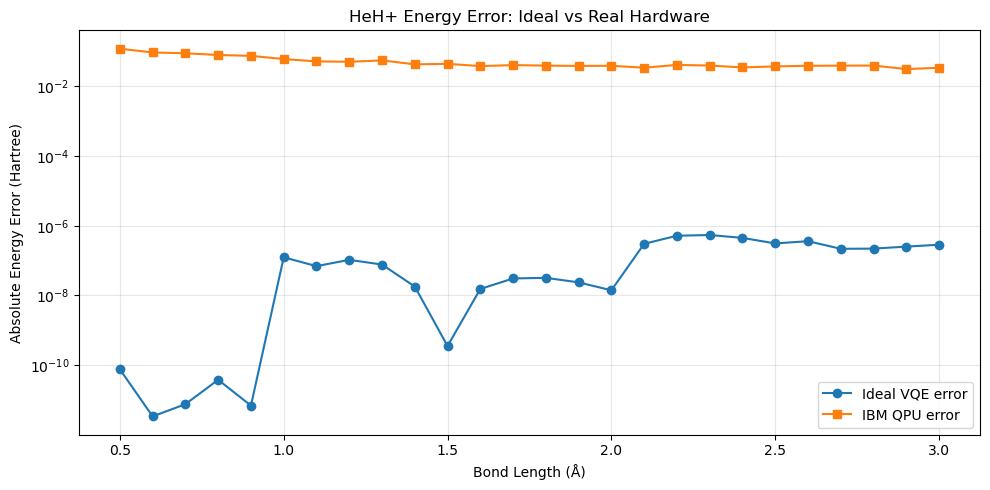

Hardware MAE: 0.05126556871470667
Hardware maximum error: 0.12050707278996153


In [90]:

plt.figure(figsize=(10, 5))

plt.plot(
    df["R"],
    abs(df["Ideal_VQE"] - df["Exact"]),
    "o-",
    label="Ideal VQE error"
)

plt.plot(
    df["R"],
    df["Hardware_abs_error"],
    "s-",
    label="IBM QPU error"
)

plt.yscale("log")
plt.xlabel("Bond Length (Å)")
plt.ylabel("Absolute Energy Error (Hartree)")
plt.title("HeH+ Energy Error: Ideal vs Real Hardware")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(
    "Hardware MAE:",
    df["Hardware_abs_error"].mean()
)

print(
    "Hardware maximum error:",
    df["Hardware_abs_error"].max()
)
